# 02 · EDA Bagian 4 — Perilaku Rekening (Arus Kas)

**Sumber data**: `account_behavior`, berisi ringkasan **bulanan** rekening nasabah di lender ini: saldo awal/akhir/rata-rata/minimum, uang masuk/keluar, kredit mirip pendapatan, dan jumlah hari saldo < Rp250 rb.

| # | Pertanyaan |
|---|---|
| Q1 | Siapa yang punya data rekening, dan seperti apa strukturnya? |
| Q2 | Apakah **level** saldo & arus kas memprediksi gagal bayar? Jendela waktu mana yang terbaik? |
| Q3 | Apakah tanda **stres likuiditas** (saldo rendah, bulan defisit) informatif? |
| Q4 | Apakah **kemampuan bayar** dari arus kas riil (cicilan vs pendapatan, bantalan saldo) informatif? |
| Q5 | Apa yang terjadi pada arus kas **bulan-bulan menjelang pengajuan**? |
| Q6 | Apakah **lonjakan pengeluaran** membawa informasi baru di luar riwayat bayar & biro? |
| Q7 | Apakah **volatilitas** dan **tren** penting? |
| Q8 | Berapa kenaikan KS dari rekening, terutama untuk segmen B? |

Fungsi `account_features` ditambahkan ke `features.py`.

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E
import features as F

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

tr = E.load("train_applications")
cp = E.load("customer_profiles")
ab = E.load("account_behavior")
bo = E.load("bureau_observations")
pa = E.load("previous_applications")
rh = E.load("repayment_history")
CUT = tr.select("application_id", "customer_id", pl.col("decision_datetime").alias("cutoff"))
cut2 = CUT.select("customer_id", "cutoff")

fa = F.account_features(ab, cut2)
df = (tr.join(cp, on="customer_id", how="left")
        .join(fa, on="customer_id", how="left")
        .join(F.bureau_features(bo, CUT, income=cp.select("customer_id", "declared_monthly_income")), on="customer_id", how="left")
        .join(F.prev_app_features(pa, cut2), on="customer_id", how="left")
        .join(F.loan_features(pa, rh, cut2), on="customer_id", how="left")
        .join(F.repayment_features(rh, cut2), on="customer_id", how="left")
        .with_columns(
            dti=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
            total_installment=pl.col("proposed_monthly_installment") + pl.col("ln_active_installment").fill_null(0),
            segment=pl.when(pl.col("pa_n").is_null()).then(pl.lit("A. tanpa riwayat"))
                      .when(pl.col("rp_n_inst").is_null()).then(pl.lit("B. ada pengajuan, belum ada cicilan"))
                      .otherwise(pl.lit("C. ada riwayat cicilan")))
        .with_columns(
            total_dti=pl.col("total_installment") / pl.col("declared_monthly_income"),
            # kemampuan bayar dari arus kas RIIL
            ac_total_inst_to_income=pl.col("total_installment") / pl.col("ac_income_6m"),
            ac_buffer_months=pl.col("ac_avg_bal_3m") / pl.col("total_installment"),
            ac_net_after_installment=(pl.col("ac_inflow_6m") - pl.col("ac_outflow_6m") - pl.col("proposed_monthly_installment"))
                                     / pl.col("ac_income_6m")))
AC = [c for c in df.columns if c.startswith("ac_")]
acc = df.filter(pl.col("ac_n_months").is_not_null())
NOISE_A = E.ks_noise_floor(acc["target"].to_numpy(), n_perm=200)
print(f"{len(AC)} fitur rekening | nasabah dengan rekening: {acc.height:,} | noise floor subset: {NOISE_A:.4f}")

42 fitur rekening | nasabah dengan rekening: 49,000 | noise floor subset: 0.0165


## Q1 · Siapa yang punya data rekening?

In [2]:
display(df.group_by("segment").agg(n=pl.len(), pct_has_account=(pl.col("ac_n_months").is_not_null().mean() * 100).round(1),
                                   median_months=pl.col("ac_n_months").median(), target_rate=pl.col("target").mean().round(4))
          .sort("segment"))
m = (ab.join(tr.select("customer_id"), on="customer_id", how="semi")
       .select(median_inflow=pl.col("inflows").median(), median_outflow=pl.col("outflows").median(),
               median_income_like=pl.col("income_like_credits").median(), median_avg_balance=pl.col("average_balance").median(),
               share_months_low_balance=(pl.col("low_balance_days") > 0).mean().round(3),
               median_out_in_ratio=(pl.col("outflows") / pl.col("inflows")).median().round(3)))
m

segment,n,pct_has_account,median_months,target_rate
str,u32,f64,f64,f64
"""A. tanpa riwayat""",21000,0.0,null,0.1172
"""B. ada pengajuan, belum ada cicilan""",2688,100.0,16.0,0.1551
"""C. ada riwayat cicilan""",46312,100.0,15.0,0.1431


median_inflow,median_outflow,median_income_like,median_avg_balance,share_months_low_balance,median_out_in_ratio
f64,f64,f64,f64,f64,f64
7694802.5,4850052.5,4.371891e6,2.5405e7,0.088,0.633


**Jawaban Q1.**
- Data rekening **hanya ada untuk nasabah lama** (segmen B & C = 70%). Segmen A (tanpa riwayat) **tidak punya rekening sama sekali**, jadi sumber ini tidak bisa membantu segmen terlemah kita.
- Setiap nasabah punya 8–23 bulan (median 15), dan bulan terakhir selalu bulan tepat sebelum bulan keputusan (audit).
- Gambaran tipikal per bulan: uang masuk ~Rp7,7 jt, keluar ~Rp4,8 jt (rasio keluar/masuk median ~0,63), dan saldo rata-rata ~Rp25 jt. Hanya ~9% bulan yang pernah menyentuh saldo < Rp250 rb.

## Q2 · Level saldo & arus kas

feature,ks,auc,arah,iv,ks_x_noise
str,f64,f64,str,f64,f64
"""ac_out_surge_1m_med""",0.1412,0.595,"""↑ nilai → ↑ risiko""",0.1104,8.6
"""ac_out_surge_3m""",0.1351,0.5921,"""↑ nilai → ↑ risiko""",0.1066,8.2
"""ac_excess_out_1m_vs_income""",0.1351,0.5908,"""↑ nilai → ↑ risiko""",0.1046,8.2
"""ac_out_surge_1m""",0.131,0.5906,"""↑ nilai → ↑ risiko""",0.0992,7.9
"""ac_outflow_3m""",0.118,0.5722,"""↑ nilai → ↑ risiko""",0.0758,7.2
"""ac_out_in_ratio_1m""",0.1173,0.5793,"""↑ nilai → ↑ risiko""",0.0798,7.1
"""ac_neg_month_share_3m""",0.1057,0.5575,"""↑ nilai → ↑ risiko""",0.0485,6.4
"""ac_out_in_ratio_3m""",0.1029,0.5755,"""↑ nilai → ↑ risiko""",0.0784,6.2
"""ac_out_surge_2m""",0.1025,0.5692,"""↑ nilai → ↑ risiko""",0.0589,6.2


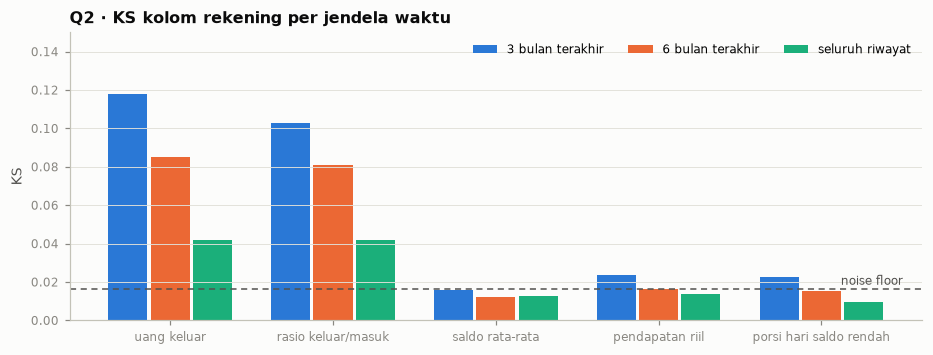

In [3]:
sig = E.signal_table(acc, AC).with_columns((pl.col("ks") / NOISE_A).round(1).alias("ks_x_noise"))
display(sig.select("feature", "ks", "auc", "arah", "iv", "ks_x_noise"))
win = []
for base_name, lab in [("ac_outflow", "uang keluar"), ("ac_out_in_ratio", "rasio keluar/masuk"), ("ac_avg_bal", "saldo rata-rata"),
                       ("ac_income", "pendapatan riil"), ("ac_low_days_share", "porsi hari saldo rendah")]:
    for tag in ("3m", "6m", "all"):
        win.append((lab, tag, E.ks_stat(acc["target"].to_numpy(), acc[f"{base_name}_{tag}"].to_numpy())))
fig, ax = plt.subplots(figsize=(10, 3.4))
labs = list(dict.fromkeys(w[0] for w in win)); xs = np.arange(len(labs)); wbar = 0.26
for j, tag in enumerate(("3m", "6m", "all")):
    vals = [next(w[2] for w in win if w[0] == l and w[1] == tag) for l in labs]
    ax.bar(xs + (j - 1) * wbar, vals, width=wbar - 0.02, color=E.SERIES[j], label={"3m": "3 bulan terakhir", "6m": "6 bulan terakhir", "all": "seluruh riwayat"}[tag])
ax.axhline(NOISE_A, color=E.INK2, lw=1, ls=(0, (4, 3)))
ax.text(len(labs) - 0.5, NOISE_A + 0.002, "noise floor", fontsize=8, color=E.INK2, ha="right")
ax.set_xticks(xs); ax.set_xticklabels(labs); ax.set_ylabel("KS"); ax.legend(ncols=3, loc="upper right")
ax.set_ylim(0, 0.15)
ax.set_title("Q2 · KS kolom rekening per jendela waktu")
plt.show()

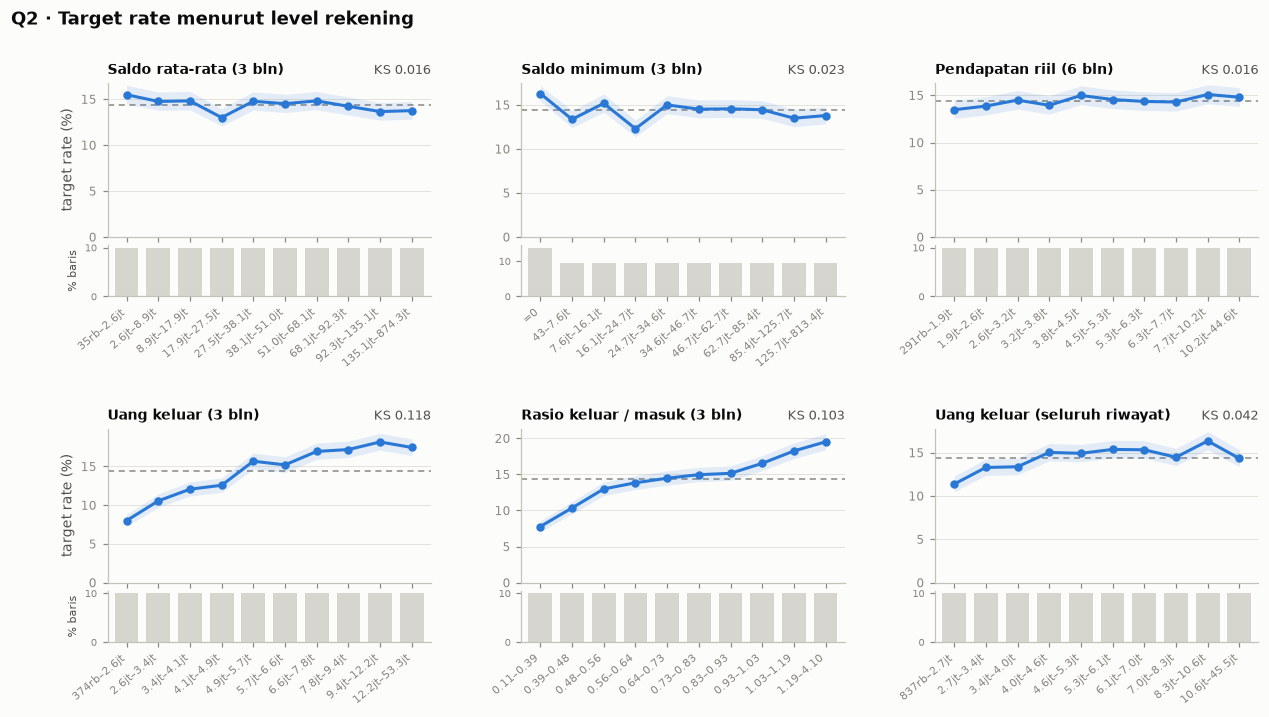

In [4]:
E.plot_rates(acc, ["ac_avg_bal_3m", "ac_min_bal_3m", "ac_income_6m", "ac_outflow_3m", "ac_out_in_ratio_3m", "ac_outflow_all"],
             titles={"ac_avg_bal_3m": "Saldo rata-rata (3 bln)", "ac_min_bal_3m": "Saldo minimum (3 bln)",
                     "ac_income_6m": "Pendapatan riil (6 bln)", "ac_outflow_3m": "Uang keluar (3 bln)",
                     "ac_out_in_ratio_3m": "Rasio keluar / masuk (3 bln)", "ac_outflow_all": "Uang keluar (seluruh riwayat)"},
             suptitle="Q2 · Target rate menurut level rekening")

**Jawaban Q2 — level saldo hampir tidak informatif; yang berbicara adalah PENGELUARAN TERBARU.**
- **Saldo** (rata-rata, minimum, penutupan) dan **pendapatan riil** semuanya di sekitar noise (KS ≤ 0,03). Nasabah kaya dan miskin saldo sama-sama bisa gagal bayar.
- **Uang keluar** dan **rasio keluar/masuk** adalah satu-satunya kolom yang jelas, dan **hanya untuk jendela terbaru**: KS ~0,10–0,12 untuk 3 bulan terakhir, ~0,08 untuk 6 bulan, ~0,04 untuk seluruh riwayat.
- Ini **kebalikan** dari repayment (Bagian 2), di mana seluruh riwayat paling kuat. Pola ini mengisyaratkan sesuatu terjadi **tepat sebelum pengajuan**, dan itu diselidiki di Q5.

## Q3 · Tanda stres likuiditas

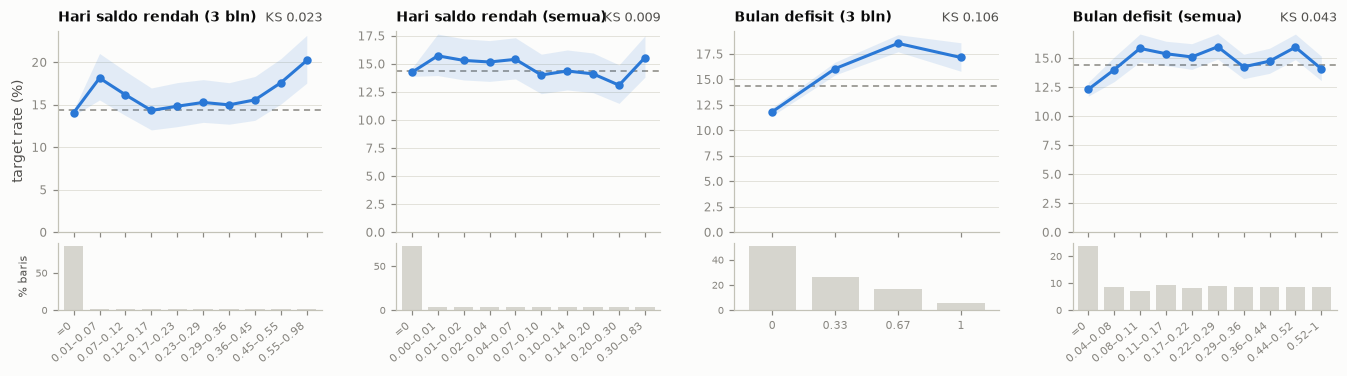

In [5]:
E.plot_rates(acc, ["ac_low_days_share_3m", "ac_low_days_share_all", "ac_neg_month_share_3m", "ac_neg_month_share_all"],
             ncols=4, width=15, titles={"ac_low_days_share_3m": "Hari saldo rendah (3 bln)", "ac_low_days_share_all": "Hari saldo rendah (semua)",
                                        "ac_neg_month_share_3m": "Bulan defisit (3 bln)", "ac_neg_month_share_all": "Bulan defisit (semua)"})

**Jawaban Q3.**
- **Hari dengan saldo < Rp250 rb** hampir tidak informatif (KS ≤ 0,02) di jendela mana pun. Saldo yang "mepet" bukan penanda risiko di data ini.
- **Porsi bulan defisit** (keluar > masuk) pada 3 bulan terakhir cukup informatif (KS ~0,11). Tapi pada seluruh riwayat lemah (~0,04), lagi-lagi menunjukkan efek **bulan-bulan terakhir**.

## Q4 · Kemampuan bayar dari arus kas riil

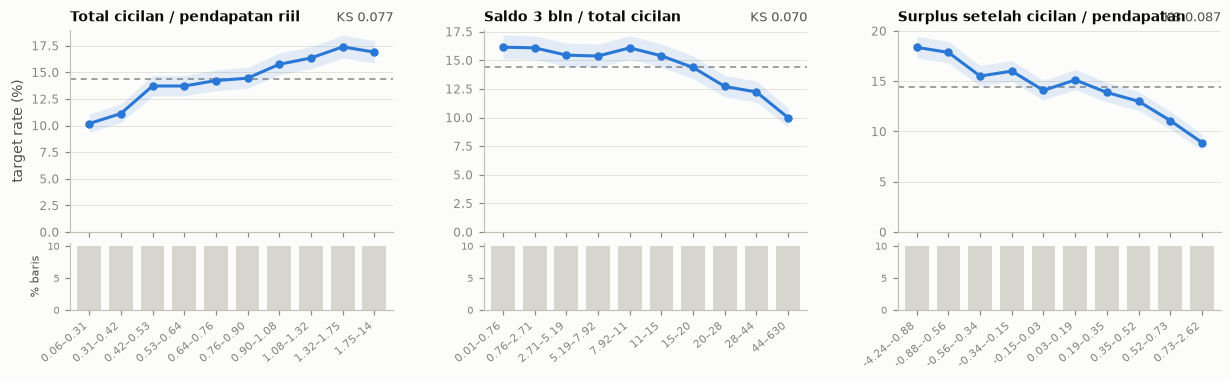

feature,ks,auc,arah
str,f64,f64,str
"""ac_net_after_installment""",0.0872,0.4382,"""↑ nilai → ↓ risiko"""
"""dti""",0.0775,0.5491,"""↑ nilai → ↑ risiko"""
"""ac_total_inst_to_income""",0.0773,0.5512,"""↑ nilai → ↑ risiko"""
"""total_dti""",0.0763,0.5483,"""↑ nilai → ↑ risiko"""
"""ac_buffer_months""",0.0699,0.4586,"""↑ nilai → ↓ risiko"""


In [6]:
E.plot_rates(acc, ["ac_total_inst_to_income", "ac_buffer_months", "ac_net_after_installment"], ncols=3,
             titles={"ac_total_inst_to_income": "Total cicilan / pendapatan riil", "ac_buffer_months": "Saldo 3 bln / total cicilan",
                     "ac_net_after_installment": "Surplus setelah cicilan / pendapatan"})
E.signal_table(acc, ["ac_total_inst_to_income", "ac_buffer_months", "ac_net_after_installment", "total_dti", "dti"]).select("feature", "ks", "auc", "arah")

**Jawaban Q4.**
- Rasio cicilan terhadap **pendapatan riil** (KS ~0,08) setara dengan DTI deklarasi. Sama seperti di Bagian 1, *affordability* hanya sinyal sekunder.
- **Bantalan saldo** (berapa bulan cicilan tertutup oleh saldo) berarah benar (makin tebal makin aman), tapi lemah (~0,07).
- **Surplus setelah cicilan** (masuk − keluar − cicilan baru, dibagi pendapatan) sedikit lebih baik (~0,09). Komponen kuncinya, lagi-lagi, adalah **uang keluar**.

## Q5 · Apa yang terjadi menjelang pengajuan?

"Studi kejadian": urutkan bulan mundur dari keputusan (k = 1 adalah bulan terakhir sebelum keputusan), lalu bandingkan nasabah yang **nantinya** gagal bayar dengan yang lancar. Agar adil antar nasabah, uang keluar setiap bulan dibagi dengan **rata-rata uang keluar nasabah itu sendiri pada bulan ke-5 s.d. ke-8** (masa "normal").

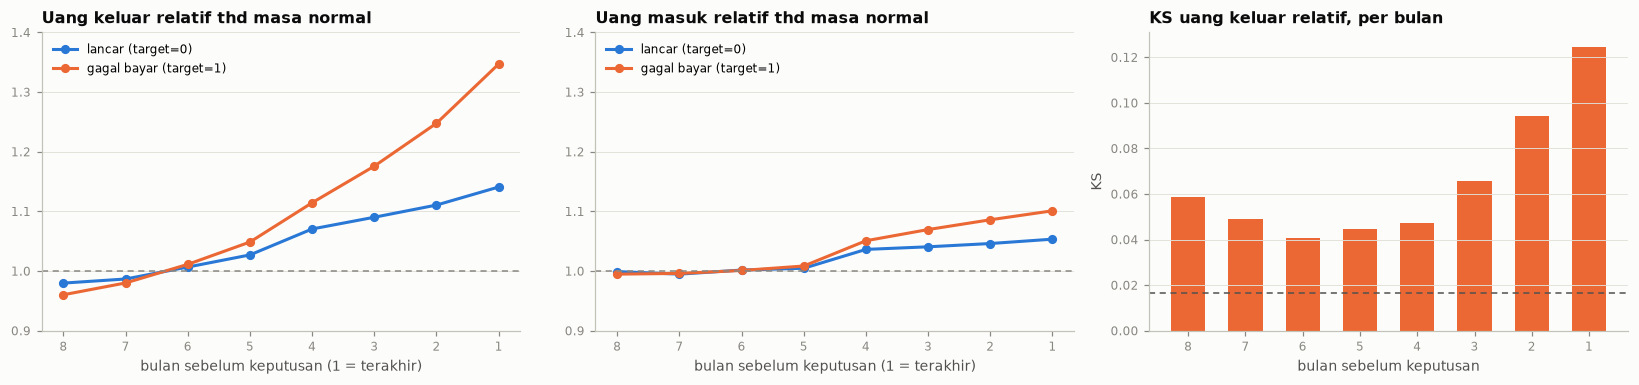

k,out_rel_0,out_rel_1,out_in_0,out_in_1
u32,f64,f64,f64,f64
1,1.141,1.347,0.704,0.829
2,1.111,1.248,0.7,0.779
3,1.09,1.176,0.697,0.744
4,1.07,1.114,0.695,0.726
5,1.027,1.049,0.701,0.725
6,1.007,1.011,0.69,0.697
7,0.987,0.98,0.682,0.679
8,0.98,0.96,0.667,0.662


In [7]:
ev = (ab.join(tr.select("customer_id", "target"), on="customer_id", how="inner")
        .sort("customer_id", "month")
        .with_columns(k=pl.col("month").rank("ordinal", descending=True).over("customer_id"))
        .filter(pl.col("k") <= 8)
        .with_columns(out_base=pl.col("outflows").filter(pl.col("k") >= 5).mean().over("customer_id"),
                      in_base=pl.col("inflows").filter(pl.col("k") >= 5).mean().over("customer_id"))
        .with_columns(out_rel=pl.col("outflows") / pl.col("out_base"), in_rel=pl.col("inflows") / pl.col("in_base"),
                      out_in=pl.col("outflows") / pl.col("inflows")))
prof = ev.group_by("k", "target").agg(out_rel=pl.col("out_rel").mean(), in_rel=pl.col("in_rel").mean(),
                                      out_in=pl.col("out_in").median()).sort("k")
ks_k = [(k, E.ks_stat(g["target"].to_numpy(), g["out_rel"].to_numpy()), E.ks_stat(g["target"].to_numpy(), g["in_rel"].to_numpy()))
        for (k,), g in sorted(ev.group_by("k"), key=lambda t: t[0][0])]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, ttl in [(axes[0], "out_rel", "Uang keluar relatif thd masa normal"), (axes[1], "in_rel", "Uang masuk relatif thd masa normal")]:
    for t, colr, lab in [(0, E.SERIES[0], "lancar (target=0)"), (1, E.SERIES[1], "gagal bayar (target=1)")]:
        s = prof.filter(pl.col("target") == t)
        ax.plot(s["k"].to_numpy(), s[col].to_numpy(), color=colr, marker="o", ms=5, label=lab)
    ax.axhline(1, color=E.MUTED, lw=1, ls=(0, (4, 3)))
    ax.set_xticks(range(1, 9)); ax.set_xlabel("bulan sebelum keputusan (1 = terakhir)"); ax.invert_xaxis()
    ax.set_ylim(0.9, 1.4); ax.set_title(ttl); ax.legend(loc="upper left")
ax = axes[2]
ax.bar([k[0] for k in ks_k], [k[1] for k in ks_k], color=E.SERIES[1], width=0.6)
ax.axhline(NOISE_A, color=E.INK2, lw=1, ls=(0, (4, 3)))
ax.set_xticks(range(1, 9)); ax.invert_xaxis(); ax.set_xlabel("bulan sebelum keputusan"); ax.set_ylabel("KS")
ax.set_title("KS uang keluar relatif, per bulan")
plt.tight_layout(); plt.show()
prof.pivot(on="target", index="k", values=["out_rel", "out_in"]).with_columns(pl.col(pl.Float64).round(3))

**Jawaban Q5 — calon gagal bayar menunjukkan LONJAKAN PENGELUARAN 1–3 bulan sebelum mengajukan pinjaman.**
- Pada masa normal (bulan ke-5 s.d. ke-8), kedua kelompok berperilaku sama.
- Mulai ~4–5 bulan sebelum keputusan, uang keluar calon gagal bayar mulai naik, lalu **makin tajam di 3 bulan terakhir**: di bulan terakhir ~1,35× masa normalnya, dibanding ~1,14× pada nasabah lancar. Rasio keluar/masuk median juga naik (~0,83 vs ~0,70).
- Uang masuk juga sedikit naik (~1,10× vs ~1,05×), tapi jauh lebih kecil daripada uang keluar. Jadi ini bukan soal pendapatan turun, melainkan **pengeluaran yang membengkak**.
- KS tertinggi di bulan terakhir (~0,125), lalu turun ke ~0,095 (bulan ke-2) dan ~0,065 (ke-3). Bulan ke-4 dan sebelumnya ~0,04–0,06. Catatan: bulan ke-5 s.d. ke-8 adalah baseline itu sendiri, jadi KS di sana sebagian merupakan artefak normalisasi.

Interpretasi bisnis: nasabah yang sedang mengalami **tekanan keuangan** (biaya mendadak, menutup kewajiban lain) lalu mengajukan pinjaman lebih rentan gagal bayar. Ini sinyal "kebutuhan mendesak" yang khas pada data rekening.

## Q6 · Apakah lonjakan pengeluaran adalah informasi BARU?

Fitur lonjakan dibandingkan dengan **baseline nasabah sendiri** (bulan k ≥ 4), lalu diuji terhadap dua sinyal terkuat kita: porsi cicilan telat (Bagian 2) dan skor biro (Bagian 3).

feature,ks,auc,arah,ks_x_noise
str,f64,f64,str,f64
"""ac_out_surge_1m_med""",0.1412,0.595,"""↑ nilai → ↑ risiko""",8.6
"""ac_out_surge_3m""",0.1351,0.5921,"""↑ nilai → ↑ risiko""",8.2
"""ac_excess_out_1m_vs_income""",0.1351,0.5908,"""↑ nilai → ↑ risiko""",8.2
"""ac_out_surge_1m""",0.131,0.5906,"""↑ nilai → ↑ risiko""",7.9
"""ac_out_in_ratio_1m""",0.1173,0.5793,"""↑ nilai → ↑ risiko""",7.1
"""ac_out_surge_2m""",0.1025,0.5692,"""↑ nilai → ↑ risiko""",6.2
"""ac_balance_change_1m""",0.0557,0.4621,"""↑ nilai → ↓ risiko""",3.4
"""ac_in_surge_1m""",0.0342,0.5201,"""↑ nilai → ↑ risiko""",2.1
"""ac_income_change_1m""",0.0198,0.507,"""↑ nilai → ↑ risiko""",1.2


Korelasi Spearman ac_out_surge_1m dengan sinyal lain:


rp_late_share,bu_score_mean,annual_interest_rate,rp_current_dpd,dti
f64,f64,f64,f64,f64
0.041,-0.008,0.019,0.161,0.002


C:\Users\TUF\AppData\Local\Temp\ipykernel_20072\1062606598.py:9: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  expected=pl.col("target").mean().over(pl.col("rp_late_share").fill_null(-1).qcut(10, allow_duplicates=True),
C:\Users\TUF\AppData\Local\Temp\ipykernel_20072\1062606598.py:10: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  pl.col("bu_score_mean").fill_null(0).qcut(5, allow_duplicates=True)),
C:\Users\TUF\AppData\Local\Temp\ipykernel_20072\1062606598.py:11: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  late_q=pl.col("rp_late_share").fill_null(-1).qcut(5, allow_duplicates=True).cast(pl.String))


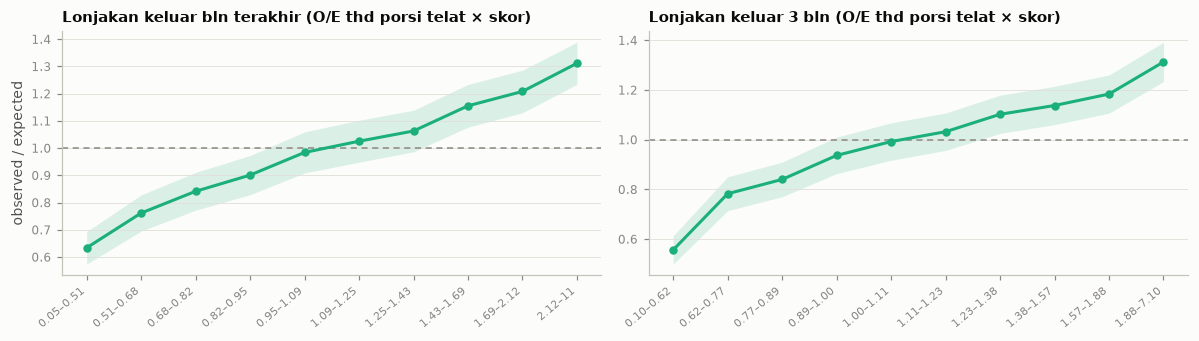

feature,ks_overall,ks_within,noise_within,excess_within
str,f64,f64,f64,f64
"""ac_out_surge_1m""",0.131,0.1426,0.0486,0.0941
"""ac_out_surge_3m""",0.1351,0.1419,0.0486,0.0933
"""ac_outflow_3m""",0.118,0.0808,0.0486,0.0322
"""ac_out_in_ratio_1m""",0.1173,0.0671,0.0486,0.0185


In [8]:
SURGE = ["ac_out_surge_1m_med", "ac_out_surge_1m", "ac_out_surge_3m", "ac_excess_out_1m_vs_income", "ac_out_in_ratio_1m",
         "ac_out_surge_2m", "ac_in_surge_1m", "ac_income_change_1m", "ac_balance_change_1m"]
display(E.signal_table(acc, SURGE).with_columns((pl.col("ks") / NOISE_A).round(1).alias("ks_x_noise"))
         .select("feature", "ks", "auc", "arah", "ks_x_noise"))
rho = acc.select([pl.corr("ac_out_surge_1m", c, method="spearman").round(3).alias(c)
                  for c in ["rp_late_share", "bu_score_mean", "annual_interest_rate", "rp_current_dpd", "dti"]])
print("Korelasi Spearman ac_out_surge_1m dengan sinyal lain:"); display(rho)
acc6 = acc.with_columns(
    expected=pl.col("target").mean().over(pl.col("rp_late_share").fill_null(-1).qcut(10, allow_duplicates=True),
                                          pl.col("bu_score_mean").fill_null(0).qcut(5, allow_duplicates=True)),
    late_q=pl.col("rp_late_share").fill_null(-1).qcut(5, allow_duplicates=True).cast(pl.String))
E.plot_oe(acc6, ["ac_out_surge_1m", "ac_out_surge_3m"], expected="expected", ncols=2, width=11, row_h=3.2,
          titles={"ac_out_surge_1m": "Lonjakan keluar bln terakhir (O/E thd porsi telat × skor)",
                  "ac_out_surge_3m": "Lonjakan keluar 3 bln (O/E thd porsi telat × skor)"})
rows = []
for f in ["ac_out_surge_1m", "ac_out_surge_3m", "ac_outflow_3m", "ac_out_in_ratio_1m"]:
    s, _ = E.ks_within(acc6, f, "late_q", n_perm=30)
    rows.append(s)
pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))

**Jawaban Q6 — ya, lonjakan pengeluaran adalah sinyal yang praktis INDEPENDEN.**
- Fitur lonjakan terbaik (`ac_out_surge_1m_med`: bulan terakhir ÷ median masa normal) mencapai KS ~0,14, sekitar 8× noise.
- Korelasinya dengan porsi telat, skor biro, dan suku bunga **hampir nol** (|ρ| ≤ 0,04). Hanya dengan tunggakan aktif ada sedikit hubungan (~0,16).
- **Setelah porsi telat × skor biro diperhitungkan**, O/E masih bergerak dari ~0,63 (pengeluaran turun) hingga ~1,31 (pengeluaran > 2× normal). Di dalam kuintil porsi telat, KS lonjakan tetap ~0,14 (noise ~0,05).
- Sebaliknya, **level** uang keluar 3 bulan dan rasio keluar/masuk sebagian besar tumpang tindih dengan sinyal lain (excess kecil). Yang baru adalah **perubahan relatif terhadap kebiasaan nasabah sendiri**, bukan levelnya.
- Uang masuk, pendapatan, dan saldo bulan terakhir relatif terhadap baseline: lemah.

## Q7 · Volatilitas & tren

In [9]:
E.signal_table(acc, ["ac_income_cv", "ac_outflow_cv_base", "ac_balance_cv", "ac_low_days_change_1m", "ac_balance_change_1m",
                     "ac_income_change_1m", "ac_n_months"]).with_columns((pl.col("ks") / NOISE_A).round(1).alias("ks_x_noise")
                    ).select("feature", "ks", "auc", "arah", "ks_x_noise")

feature,ks,auc,arah,ks_x_noise
str,f64,f64,str,f64
"""ac_outflow_cv_base""",0.0877,0.5583,"""↑ nilai → ↑ risiko""",5.3
"""ac_balance_change_1m""",0.0557,0.4621,"""↑ nilai → ↓ risiko""",3.4
"""ac_income_cv""",0.042,0.5258,"""↑ nilai → ↑ risiko""",2.5
"""ac_low_days_change_1m""",0.0266,0.5197,"""↑ nilai → ↑ risiko""",1.6
"""ac_balance_cv""",0.026,0.493,"""↑ nilai → ↓ risiko""",1.6
"""ac_income_change_1m""",0.0198,0.507,"""↑ nilai → ↑ risiko""",1.2
"""ac_n_months""",0.0061,0.4971,"""↑ nilai → ↓ risiko""",0.4


**Jawaban Q7.**
- **Volatilitas pengeluaran pada masa normal** (`ac_outflow_cv_base`, KS ~0,09) cukup informatif: nasabah yang pengeluarannya memang tidak stabil lebih berisiko.
- **Perubahan saldo bulan terakhir** vs masa normal sinyal sedang (~0,06): saldo yang turun lebih berisiko, sejalan dengan lonjakan pengeluaran.
- Volatilitas pendapatan riil tipis (~0,04, konsisten dengan Bagian 1). Volatilitas saldo, perubahan pendapatan, dan lama riwayat rekening ≈ lemah/noise.

## Q8 · Kontribusi rekening terhadap KS

In [10]:
CATS = ["loan_purpose", "region", "employment_type", "housing_status", "segment"]
BASE = ["annual_interest_rate", "loan_amount", "proposed_monthly_installment", "loan_purpose", "age", "region",
        "employment_type", "employment_tenure_months", "declared_monthly_income", "dependents", "housing_status", "dti"]
INTERNAL = [c for c in df.columns if c.startswith(("pa_", "ln_", "rp_")) and c != "pa_last_decision"] + ["total_dti", "segment"]
BU = [c for c in df.columns if c.startswith("bu_")]
SURGE5 = ["ac_out_surge_1m_med", "ac_out_surge_3m", "ac_out_surge_1m", "ac_excess_out_1m_vs_income", "ac_out_in_ratio_1m"]
configs = {
    "1. riwayat internal + biro (Bagian 3)": BASE + INTERNAL + BU,
    "2. + 5 fitur lonjakan saja": BASE + INTERNAL + BU + SURGE5,
    "3. + semua fitur rekening": BASE + INTERNAL + BU + AC,
}
has_ac = df["ac_n_months"].is_not_null().to_numpy()
yy = df["target"].to_numpy()
res, imps = [], {}
for seed in (42, 7):
    for name, feats in configs.items():
        oof, ks, auc, imp = E.cv_lgb(df, feats, cat_features=[c for c in CATS if c in feats], seed=seed)
        scored = df.select("segment", "target").with_columns(oof=pl.Series(oof))
        seg = {k[0][:1]: round(E.ks_stat(g["target"].to_numpy(), g["oof"].to_numpy()), 4) for k, g in scored.group_by("segment")}
        res.append(dict(seed=seed, config=name, n_features=len(feats), ks_oof=round(ks, 4), auc_oof=round(auc, 4),
                        ks_has_account=round(E.ks_stat(yy[has_ac], oof[has_ac]), 4),
                        ks_seg_A=seg["A"], ks_seg_B=seg["B"], ks_seg_C=seg["C"]))
        imps[(seed, name)] = imp
res = pl.DataFrame(res)
display(res)
display(res.group_by("config", maintain_order=True).agg(pl.col("ks_oof", "auc_oof", "ks_has_account", "ks_seg_A", "ks_seg_B", "ks_seg_C").mean().round(4)))
imps[(42, "3. + semua fitur rekening")].filter(pl.col("feature").str.starts_with("ac_")).head(12).with_columns(pl.col("gain_pct").round(2))

seed,config,n_features,ks_oof,auc_oof,ks_has_account,ks_seg_A,ks_seg_B,ks_seg_C
i64,str,i64,f64,f64,f64,f64,f64,f64
42,"""1. riwayat internal + biro (Bagian 3)""",92,0.4181,0.787,0.4816,0.2487,0.2671,0.4945
42,"""2. + 5 fitur lonjakan saja""",97,0.4248,0.7896,0.4914,0.2459,0.3473,0.5024
42,"""3. + semua fitur rekening""",134,0.4255,0.7906,0.4926,0.2494,0.342,0.5027
7,"""1. riwayat internal + biro (Bagian 3)""",92,0.4194,0.7872,0.4843,0.2472,0.2697,0.4971
7,"""2. + 5 fitur lonjakan saja""",97,0.4238,0.7894,0.4892,0.2449,0.34,0.4989
7,"""3. + semua fitur rekening""",134,0.4257,0.7907,0.4917,0.2452,0.3377,0.5019


config,ks_oof,auc_oof,ks_has_account,ks_seg_A,ks_seg_B,ks_seg_C
str,f64,f64,f64,f64,f64,f64
"""1. riwayat internal + biro (Bagian 3)""",0.4188,0.7871,0.483,0.248,0.2684,0.4958
"""2. + 5 fitur lonjakan saja""",0.4243,0.7895,0.4903,0.2454,0.3436,0.5006
"""3. + semua fitur rekening""",0.4256,0.7906,0.4922,0.2473,0.3398,0.5023


feature,gain_pct
str,f64
"""ac_out_surge_3m""",1.1
"""ac_out_surge_1m""",0.97
"""ac_out_surge_1m_med""",0.9
"""ac_outflow_3m""",0.73
"""ac_income_cv""",0.73
"""ac_excess_out_1m_vs_income""",0.7
"""ac_out_surge_2m""",0.68
"""ac_outflow_6m""",0.68
"""ac_out_in_ratio_1m""",0.65


**Jawaban Q8** (rata-rata 2 seed, karena selisihnya kecil).
- **5 fitur lonjakan saja** menaikkan KS keseluruhan sekitar **+0,005** (rata-rata ≈ 0,419 → ~0,424). Pada nasabah yang punya rekening, kenaikannya sekitar **+0,007** (0,483 → 0,490). Kecil, tapi konsisten di kedua seed.
- **Semua fitur rekening** (+37 fitur) hanya menambah ~0,001 lagi (~0,426), masih di dalam noise. Puluhan fitur level/stres lainnya praktis tidak menambah apa-apa, jadi lebih baik memakai set fitur yang ramping.
- **Segmen B** (pengajuan tanpa cicilan) mendapat manfaat terbesar: KS naik dari ~0,27 ke ~0,34, karena bagi mereka rekening adalah satu-satunya data perilaku. Segmen C naik sedikit (~0,50). **Segmen A tidak berubah** (tidak punya rekening).

## Ringkasan Bagian 4

| Temuan | Implikasi untuk feature engineering |
|---|---|
| Rekening hanya ada untuk nasabah lama (70%); segmen A tidak punya | Rekening tidak membantu segmen terlemah; fokus segmen A tetap pada biro & e-commerce |
| Level saldo, pendapatan riil, hari saldo rendah ≈ noise | Jangan buang waktu merekayasa fitur saldo |
| Pengeluaran **terbaru** informatif; seluruh riwayat tidak (kebalikan dari repayment) | Fitur rekening harus berfokus pada **bulan-bulan terakhir** |
| **Lonjakan pengeluaran 1–3 bln sebelum pengajuan** (gagal bayar ~1,35× normal vs ~1,14×) | Fitur inti: pengeluaran bulan terakhir ÷ baseline nasabah sendiri (mean/median bulan k ≥ 4), rata-rata 3 bulan ÷ baseline, kelebihan pengeluaran ÷ pendapatan |
| Lonjakan ⟂ porsi telat, skor biro, suku bunga (ρ ≈ 0) | Sinyal baru yang melengkapi model, bukan duplikasi |
| Volatilitas pengeluaran masa normal cukup informatif | Masukkan `ac_outflow_cv_base` |
| Affordability berbasis arus kas ≈ DTI | Tidak perlu banyak varian |
| KS: ~0,419 → **~0,424–0,426**; segmen B ~0,27 → ~0,34 | Set fitur rekening ramping (~5–10 fitur) cukup |

**Hipotesis untuk Bagian 5**: apakah pola "tekanan menjelang pengajuan" juga terlihat di **e-commerce** (misalnya lonjakan belanja, pergeseran ke COD, atau pembatalan)? Kalau ya, itu akan sangat berharga karena e-commerce tersedia untuk **semua** nasabah, termasuk segmen A.